## Team
Aden Thompson

Cody Reep

11/24/2026

## Description

**Description**

In this project, our team loaded Abdelhamid et al.’s (2014) Website Phishing dataset from the UC Irvine Machine Learning Repository. The dataset contains 1353 instances with
9 features each. Each instance corresponds to a website, while the features correspond to an aspect of that website, like its URL length, pop up windows, and the age of its domain. The target feature, Result, is whether the website as a whole is legitimate (1), suspicious (0), or “phishy” (-1). The input features are whether specific aspects of the website are legitimate, suspicious, or phishy.

Since all values within this dataset are -1, 0, or 1, typical preprocessing steps like feature scaling and encoding were unnecessary. Additionally, no features were dropped. The dataset was split into a training and testing set using StratifiedShuffleSplit (80/20).

**Analysis with conclusion**

We tested three models. First, we tested sklearn’s classification SVM model (SVC) with a Gaussian Radial Basis Function (RBF) kernel with gamma set to auto, C set to 1000, and a degree of 3. Second, we tested a linear SVC from sklearn with C set to 1000. Third, we tested sklearn’s DecisionTreeClassifier (max depth of 8). On the 271-entry testing set, RBF SVC performed best with 86.0% accuracy, precision, and recall scores. The linear SVC achieved an 84.0% accuracy score, 78.0% precision score, and an 84.0% recall score. The decision tree’s performance was similar,  yielding an 83.0% accuracy score, 80.0% precision score, and 83.0% recall score. Based on these findings, we conclude that the RBC SVC model is the best choice under these model parameter conditions.

However, we observed that the performance on the cross-validation training and testing sets was dependent on the model parameters selected. Therefore, the results of this testing are conditional on the parameters specified. Using grid search cross-validation to find the optimal parameter values for each of these models would provide a more general conclusion about the performance of these models on this dataset.

Source: https://www.sciencedirect.com/science/article/abs/pii/S0957417414001481


In [1]:
# Import libraries that are needed to train and test the model
import pandas as pd
from pandas.plotting import scatter_matrix
from sklearn.model_selection import StratifiedShuffleSplit, cross_val_predict
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_score, recall_score, confusion_matrix, accuracy_score

In [2]:
# Import the dataset
# Get the data
data_path = "https://archive.ics.uci.edu/static/public/379/data.csv"
def load_phishing_data():
    csv_path = data_path
    return pd.read_csv(csv_path, sep=',', low_memory=False)

In [3]:
# Set the phishing variable equal to the pd dataframe provided by the load data function
phishing = load_phishing_data()

## Inspect Data

In [4]:
# View the info of the phishing dataframe
phishing.info()

<class 'pandas.DataFrame'>
RangeIndex: 1353 entries, 0 to 1352
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   SFH                1353 non-null   int64
 1   popUpWindow        1353 non-null   int64
 2   SSLfinal_State     1353 non-null   int64
 3   Request_URL        1353 non-null   int64
 4   URL_of_Anchor      1353 non-null   int64
 5   web_traffic        1353 non-null   int64
 6   URL_Length         1353 non-null   int64
 7   age_of_domain      1353 non-null   int64
 8   having_IP_Address  1353 non-null   int64
 9   Result             1353 non-null   int64
dtypes: int64(10)
memory usage: 105.8 KB


In [5]:
# View the description of the phishing dataframe
phishing.describe(include="all")

,SFH,popUpWindow,SSLfinal_State,Request_URL,URL_of_Anchor,web_traffic,URL_Length,age_of_domain,having_IP_Address,Result
count,1353.000000,1353.000000,1353.000000,1353.000000,1353.000000,1353.000000,1353.000000,1353.000000,1353.000000,1353.000000
mean,0.237990,-0.258684,0.327421,-0.223208,-0.025129,0.000000,-0.053215,0.219512,0.114560,-0.113821
std,0.916389,0.679072,0.822193,0.799682,0.936262,0.806776,0.762552,0.975970,0.318608,0.954773
min,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,0.000000,-1.000000
25%,-1.000000,-1.000000,0.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,0.000000,-1.000000
50%,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,-1.000000
75%,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [6]:
# View the first five observations of the phishing dataframe
phishing.head()

,SFH,popUpWindow,SSLfinal_State,Request_URL,URL_of_Anchor,web_traffic,URL_Length,age_of_domain,having_IP_Address,Result
0,1,-1,1,-1,-1,1,1,1,0,0
1,-1,-1,-1,-1,-1,0,1,1,1,1
2,1,-1,0,0,-1,0,-1,1,0,1
3,1,0,1,-1,-1,0,1,1,0,0
4,-1,-1,1,-1,0,0,-1,1,0,1


In [7]:
# View the last five observations of the phishing dataframe
phishing.tail()

,SFH,popUpWindow,SSLfinal_State,Request_URL,URL_of_Anchor,web_traffic,URL_Length,age_of_domain,having_IP_Address,Result
1348,-1,-1,-1,-1,-1,-1,0,1,0,1
1349,-1,0,1,0,-1,0,0,1,0,-1
1350,-1,0,-1,-1,-1,0,-1,-1,0,1
1351,0,0,1,0,0,0,-1,1,0,1
1352,1,0,1,1,1,0,-1,-1,0,-1


In [8]:
# Get the shape of the phishing dataframe
phishing.shape

(1353, 10)

## Visualize the Data

array([[<Axes: xlabel='SFH', ylabel='SFH'>,
        <Axes: xlabel='popUpWindow', ylabel='SFH'>,
        <Axes: xlabel='SSLfinal_State', ylabel='SFH'>,
        <Axes: xlabel='Request_URL', ylabel='SFH'>,
        <Axes: xlabel='URL_of_Anchor', ylabel='SFH'>,
        <Axes: xlabel='web_traffic', ylabel='SFH'>,
        <Axes: xlabel='URL_Length', ylabel='SFH'>,
        <Axes: xlabel='age_of_domain', ylabel='SFH'>,
        <Axes: xlabel='having_IP_Address', ylabel='SFH'>,
        <Axes: xlabel='Result', ylabel='SFH'>],
       [<Axes: xlabel='SFH', ylabel='popUpWindow'>,
        <Axes: xlabel='popUpWindow', ylabel='popUpWindow'>,
        <Axes: xlabel='SSLfinal_State', ylabel='popUpWindow'>,
        <Axes: xlabel='Request_URL', ylabel='popUpWindow'>,
        <Axes: xlabel='URL_of_Anchor', ylabel='popUpWindow'>,
        <Axes: xlabel='web_traffic', ylabel='popUpWindow'>,
        <Axes: xlabel='URL_Length', ylabel='popUpWindow'>,
        <Axes: xlabel='age_of_domain', ylabel='popUpWindow'>,
  

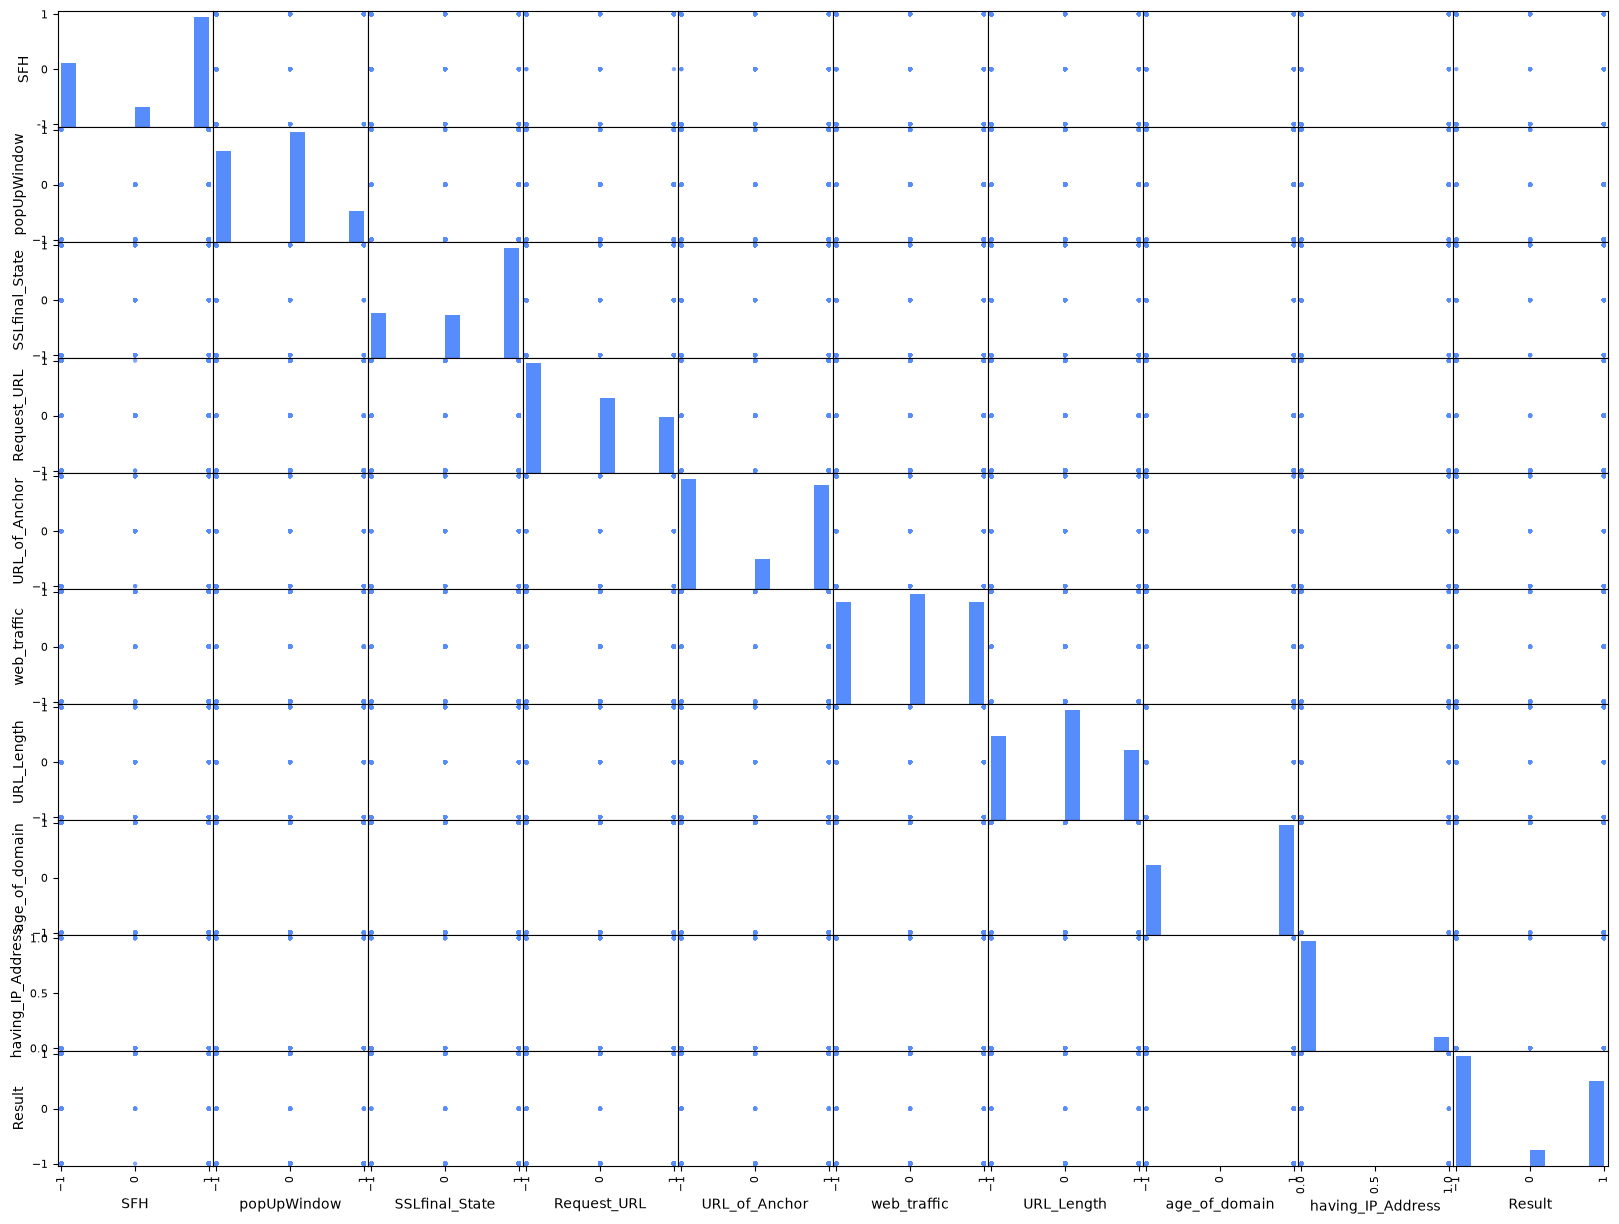

In [11]:
# Create a scatter plot matrix for the features
scatter_matrix(phishing[["SFH", "popUpWindow", "SSLfinal_State", "Request_URL", "URL_of_Anchor", "web_traffic", "URL_Length", "age_of_domain", "having_IP_Address", "Result"]], figsize=(20, 15))

## Split the data into test and train sets

In [12]:
# Split the dataset using a stratified split
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for train_index, test_index in split.split(phishing, phishing["Result"]):
    strat_train_set = phishing.loc[train_index]
    strat_test_set = phishing.loc[test_index]

In [13]:
# View the info of the train set
strat_train_set.info()

<class 'pandas.DataFrame'>
Index: 1082 entries, 777 to 600
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   SFH                1082 non-null   int64
 1   popUpWindow        1082 non-null   int64
 2   SSLfinal_State     1082 non-null   int64
 3   Request_URL        1082 non-null   int64
 4   URL_of_Anchor      1082 non-null   int64
 5   web_traffic        1082 non-null   int64
 6   URL_Length         1082 non-null   int64
 7   age_of_domain      1082 non-null   int64
 8   having_IP_Address  1082 non-null   int64
 9   Result             1082 non-null   int64
dtypes: int64(10)
memory usage: 93.0 KB


In [14]:
# View the info of the test set
strat_test_set.info()

<class 'pandas.DataFrame'>
Index: 271 entries, 12 to 942
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   SFH                271 non-null    int64
 1   popUpWindow        271 non-null    int64
 2   SSLfinal_State     271 non-null    int64
 3   Request_URL        271 non-null    int64
 4   URL_of_Anchor      271 non-null    int64
 5   web_traffic        271 non-null    int64
 6   URL_Length         271 non-null    int64
 7   age_of_domain      271 non-null    int64
 8   having_IP_Address  271 non-null    int64
 9   Result             271 non-null    int64
dtypes: int64(10)
memory usage: 23.3 KB


## Preprocess the Data

## Feature scaling and encoding

There is no need scale or encode the data in this data set. All values are either -1, 0, or 1. It also contains no text data. All features are numerical.

# Train the model

In [15]:
# Get the features (columns used in prediction) and the target (what you are trying to predict) from the train set
X_train = strat_train_set.drop("Result", axis=1) # Drop Result column from features
Y_train = strat_train_set["Result"].copy() # Copy Result column for target

In [16]:
# Get the features (columns used in prediction) and the target (what you are trying to predict) from the test set
X_test = strat_test_set.drop("Result", axis=1) # Drop Result column from features
Y_test = strat_test_set["Result"].copy() # Copy Result column for target

In [17]:
# Get the SVM model for classification with a kernel
rbf_kernel_svm_clf = SVC(kernel="rbf", gamma='auto', C=1000, degree=3, random_state=42) #gama auto from scikit docs

# Fit the model to the train set
rbf_kernel_svm_clf.fit(X_train, Y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'auto'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [18]:
# Get the SVM model for classification without a kernel
linear_svm_clf = SVC(kernel="linear", C=1000) # Ch. 7, Slide 38: linear = no kernel
# Fit the model to the train set
linear_svm_clf.fit(X_train, Y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [48]:
# Get the decision tree classifier
tree_clf = DecisionTreeClassifier(max_depth=8, random_state=42)

# Fit the model to the train set
tree_clf.fit(X_train, Y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

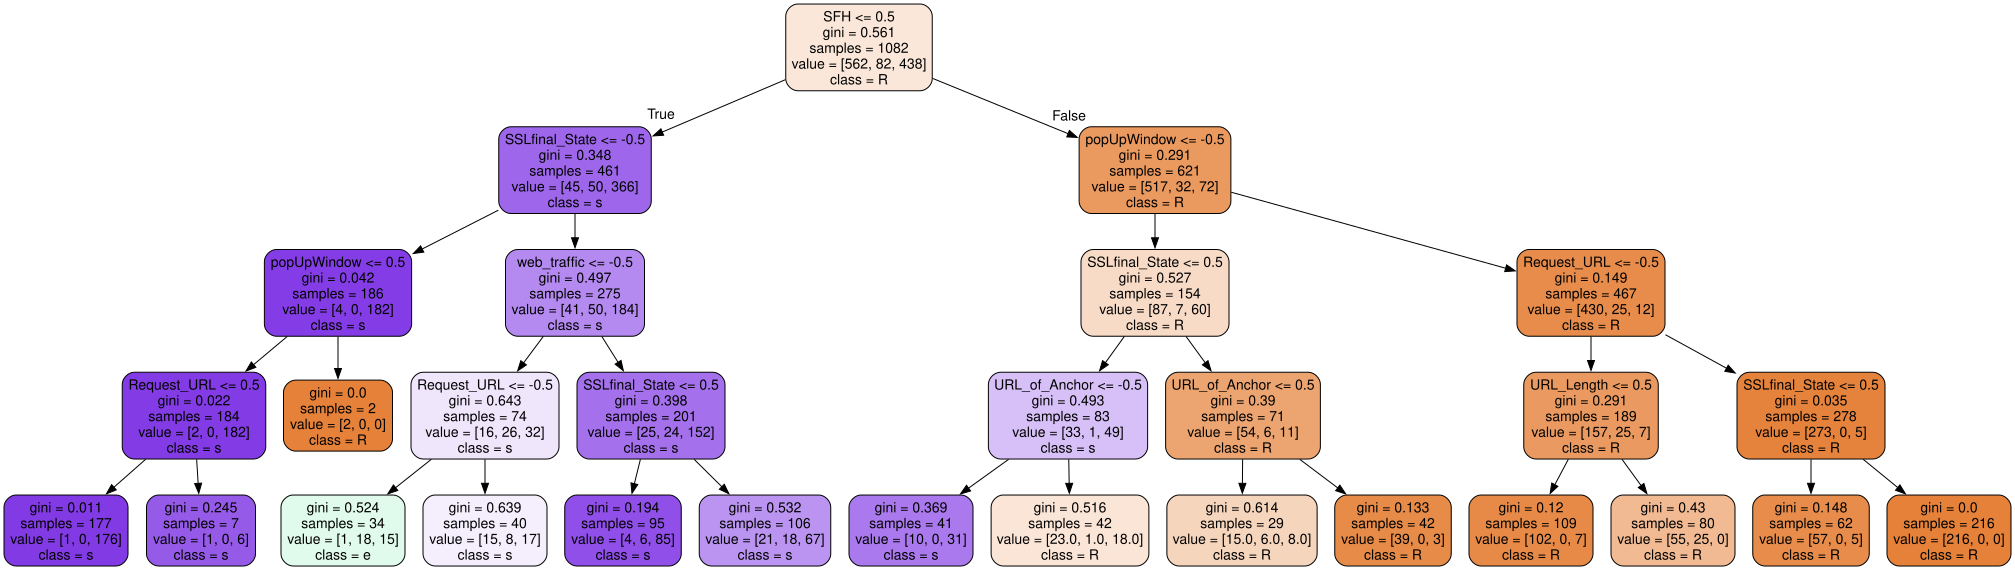

In [35]:
# Import libraries needed for tree visualization from Ch. 6: Decision Trees
from graphviz import Source
from sklearn.tree import export_graphviz
import os

# Directory where the image is saved
PROJECT_ROOT_DIR = "."
CHAPTER_ID = "decision_trees"
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images", CHAPTER_ID)

# Export the image
export_graphviz(
        tree_clf,
        out_file=os.path.join(IMAGES_PATH, "tree.dot"),
        feature_names=X_train.columns.tolist(),
        class_names=list(Y_train.name),
        rounded=True,
        filled=True
    )

# Load the image
Source.from_file(os.path.join(IMAGES_PATH, "tree.dot"))

## Evaluation of the Model

In [36]:
# Get the predictions of the model on the train set.
# SVM with a kernel predictions
Y_pred_rbf = rbf_kernel_svm_clf.predict(X_train)
# SVM without a kernel predictions
Y_pred_linear = linear_svm_clf.predict(X_train)
# Decision tree predictions
Y_pred_tree = tree_clf.predict(X_train)

In [37]:
# Evaluate the SVM model with a kernel on the train dataset
print("SVM with kernel:")
# Accuracy
print("Accuracy:" + str(round(accuracy_score(Y_train, Y_pred_rbf), 2)))
# Precision
print("Precision:" +  str(round(precision_score(Y_train, Y_pred_rbf, average="weighted"), 2))) # Source: https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html
# Recall
print("Recall:" +  str(round(recall_score(Y_train, Y_pred_rbf, average="weighted"), 2)))
# Confusion matrix
confusion_matrix(Y_train, Y_pred_rbf)

SVM with kernel:
Accuracy:0.96
Precision:0.96
Recall:0.96


array([[534,   6,  22],
       [  0,  80,   2],
       [  9,   3, 426]])

In [38]:
# Evaluate the SVM model without a kernel on the train dataset
print("SVM without kernel:")
# Accuracy
print("Accuracy:" + str(round(accuracy_score(Y_train, Y_pred_linear), 2)))
# Precision
print("Precision:" +  str(round(precision_score(Y_train, Y_pred_linear, average="weighted"), 2)))
# Recall
print("Recall:" +  str(round(recall_score(Y_train, Y_pred_linear, average="weighted"), 2)))
# Confusion matrix
confusion_matrix(Y_train, Y_pred_linear)

SVM without kernel:
Accuracy:0.85
Precision:0.84
Recall:0.85


array([[518,   0,  44],
       [ 33,  13,  36],
       [ 50,   3, 385]])

In [39]:
# Evaluate the decision tree on the train dataset
print("Decision tree:")
# Accuracy
print("Accuracy:" + str(round(accuracy_score(Y_train, Y_pred_tree), 2)))
# Precision
print("Precision:" +  str(round(precision_score(Y_train, Y_pred_tree, average="weighted", zero_division=0.0), 2))) # zero_division from warning and scikit docs
# Recall
print("Recall:" +  str(round(recall_score(Y_train, Y_pred_tree, average="weighted"), 2)))
# Confusion matrix
confusion_matrix(Y_train, Y_pred_tree)

Decision tree:
Accuracy:0.84
Precision:0.83
Recall:0.84


array([[509,   1,  52],
       [ 32,  18,  32],
       [ 41,  15, 382]])

## Improved Evaluation of the Model

In [40]:
# Get cross-validation predictions for evaluation
# SVM with a kernel predictions
Y_cross_pred_rbf = cross_val_predict(rbf_kernel_svm_clf, X_train, Y_train, cv=3)
# SVM without a kernel predictions
Y_cross_pred_linear = cross_val_predict(linear_svm_clf, X_train, Y_train, cv=3)
# Decision tree predictions
Y_cross_pred_tree = cross_val_predict(tree_clf, X_train, Y_train, cv=3)

In [41]:
# Evaluate the SVM model with a kernel on the train dataset using CV
print("SVM with kernel:")
# Accuracy
print("Accuracy:" + str(round(accuracy_score(Y_train, Y_cross_pred_rbf), 4)))
# Precision
print("Precision:" +  str(round(precision_score(Y_train, Y_cross_pred_rbf, average="weighted"), 2)))
# Recall
print("Recall:" +  str(round(recall_score(Y_train, Y_cross_pred_rbf, average="weighted"), 2)))
# Confusion matrix
confusion_matrix(Y_train, Y_cross_pred_rbf)

SVM with kernel:
Accuracy:0.866
Precision:0.87
Recall:0.87


array([[500,  10,  52],
       [ 11,  61,  10],
       [ 48,  14, 376]])

In [42]:
# Evaluate the SVM model without a kernel on the train dataset using CV
print("SVM without kernel:")
# Accuracy
print("Accuracy:" + str(round(accuracy_score(Y_train, Y_cross_pred_linear), 2)))
# Precision
print("Precision:" +  str(round(precision_score(Y_train, Y_cross_pred_linear, average="weighted"), 2)))
# Recall
print("Recall:" +  str(round(recall_score(Y_train, Y_cross_pred_linear, average="weighted"), 2)))
# Confusion matrix
confusion_matrix(Y_train, Y_cross_pred_linear)

SVM without kernel:
Accuracy:0.83
Precision:0.82
Recall:0.83


array([[515,   0,  47],
       [ 33,  10,  39],
       [ 60,   5, 373]])

In [49]:
# Evaluate the decision tree model on the train dataset using CV
print("Decision tree:")
# Accuracy
print("Accuracy:" + str(round(accuracy_score(Y_train, Y_cross_pred_tree), 2)))
# Precision
print("Precision:" +  str(round(precision_score(Y_train, Y_cross_pred_tree, average="weighted", zero_division=0.0), 2))) #zero_division from warning and scikit docs
# Recall
print("Recall:" +  str(round(recall_score(Y_train, Y_cross_pred_tree, average="weighted"), 2)))
# Confusion matrix
confusion_matrix(Y_train, Y_cross_pred_tree)

Decision tree:
Accuracy:0.83
Precision:0.81
Recall:0.83


array([[514,   1,  47],
       [ 37,  12,  33],
       [ 56,   9, 373]])

## Evaluate the Model on the Test Set

In [44]:
# Evaluate the models on the testing dataset.
# SVM with a kernel predictions
Y_final_pred_rbf = rbf_kernel_svm_clf.predict(X_test)
# SVM without a kernel predictions
Y_final_pred_linear = linear_svm_clf.predict(X_test)
# Decision tree predictions
Y_final_pred_tree = tree_clf.predict(X_test)

In [65]:
# Evaluate the SVM model with a kernel on the test dataset
print("SVM with kernel:")
# Accuracy
print("Accuracy:" + str(round(accuracy_score(Y_test, Y_final_pred_rbf), 2)))
# Precision
print("Precision:" +  str(round(precision_score(Y_test, Y_final_pred_rbf, average="weighted"), 2)))
# Recall
print("Recall:" +  str(round(recall_score(Y_test, Y_final_pred_rbf, average="weighted"), 2)))
# Confusion matrix
confusion_matrix(Y_test, Y_final_pred_rbf)

SVM with kernel:
Accuracy:0.86
Precision:0.86
Recall:0.86


array([[124,   1,  15],
       [  3,  15,   3],
       [ 13,   2,  95]])

In [51]:
# Evaluate the SVM model without a kernel on the test dataset
print("SVM without kernel:")
# Accuracy
print("Accuracy:" + str(round(accuracy_score(Y_test, Y_final_pred_linear), 2)))
# Precision
print("Precision:" + str(round(precision_score(Y_test, Y_final_pred_linear, average="weighted"), 2)))
# Recall
print("Recall:" + str(round(recall_score(Y_test, Y_final_pred_linear, average="weighted"), 2)))
# Confusion matrix
confusion_matrix(Y_test, Y_final_pred_linear)

SVM without kernel:
Accuracy:0.84
Precision:0.78
Recall:0.84


array([[126,   2,  12],
       [ 14,   0,   7],
       [  8,   0, 102]])

In [53]:
# Evaluate the decision tree model on the test dataset
print("Decision tree:")
# Accuracy
print("Accuracy:" + str(round(accuracy_score(Y_test, Y_final_pred_tree), 2)))
# Precision
print("Precision:" + str(round(precision_score(Y_test, Y_final_pred_tree, average="weighted",zero_division=0.0), 2)))
# Recall
print("Recall:" + str(round(recall_score(Y_test, Y_final_pred_tree, average="weighted"), 2)))
# Confusion matrix
confusion_matrix(Y_test, Y_final_pred_tree)

Decision tree:
Accuracy:0.83
Precision:0.8
Recall:0.83


array([[123,   2,  15],
       [ 11,   2,   8],
       [  7,   3, 100]])